# 06. What drives the models? SHAP, grouped by pressure, checked against the EA's investigators

SHAP values split each prediction (in log-odds of good status) into additive contributions from each
feature. For trees, `TreeExplainer` computes them exactly. Correlated features share credit
arbitrarily, so contributions are summed into **pressure groups**: storm overflows, sewage works,
private sewage, arable, grassland, urban land, trade and fish farms, and the natural setting.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))

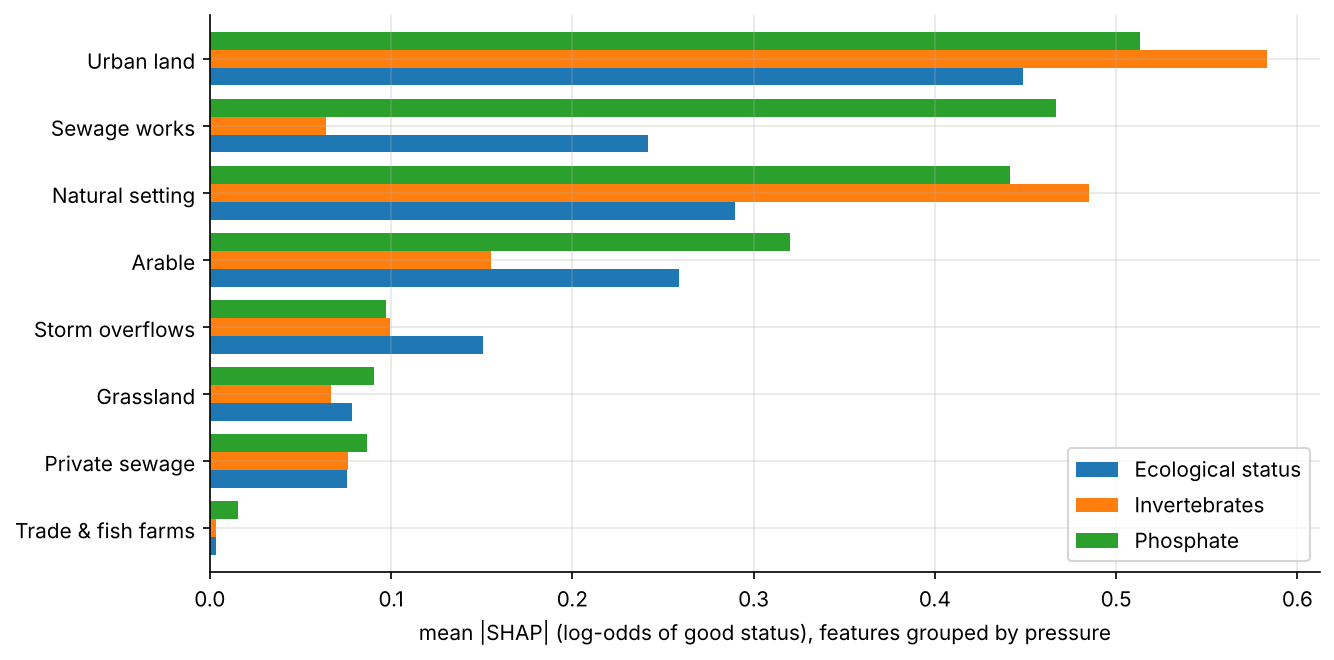

In [2]:
display(Image(FIG / "shap_groups.png"))

In [3]:
rows = {}
for tg in ["eco_good", "inv_good", "phos_good"]:
    g = pd.read_parquet(T / f"shap_groups_{tg}.parquet").drop(columns="water_body_id")
    rows[tg] = (g.abs().mean() / g.abs().mean().sum())
pd.DataFrame(rows).round(3).sort_values("phos_good", ascending=False)

,eco_good,inv_good,phos_good
Urban land,0.290,0.380,0.253
Sewage works,0.156,0.042,0.230
Natural setting,0.187,0.316,0.217
Arable,0.167,0.101,0.158
Storm overflows,0.097,0.065,0.048
Grassland,0.051,0.044,0.045
Private sewage,0.049,0.050,0.043
Trade & fish farms,0.002,0.002,0.008


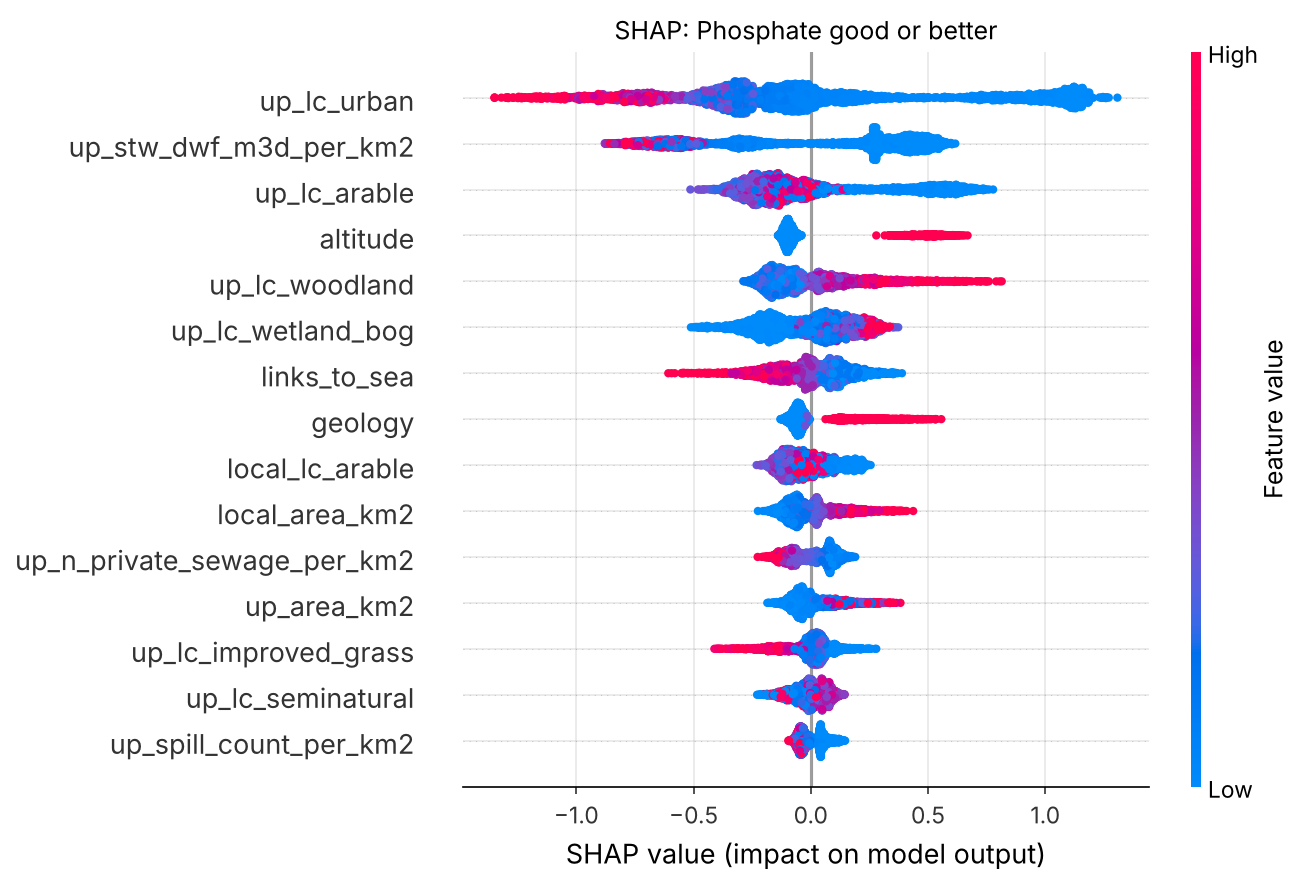

In [4]:
display(Image(FIG / "shap_beeswarm_phos_good.png"))

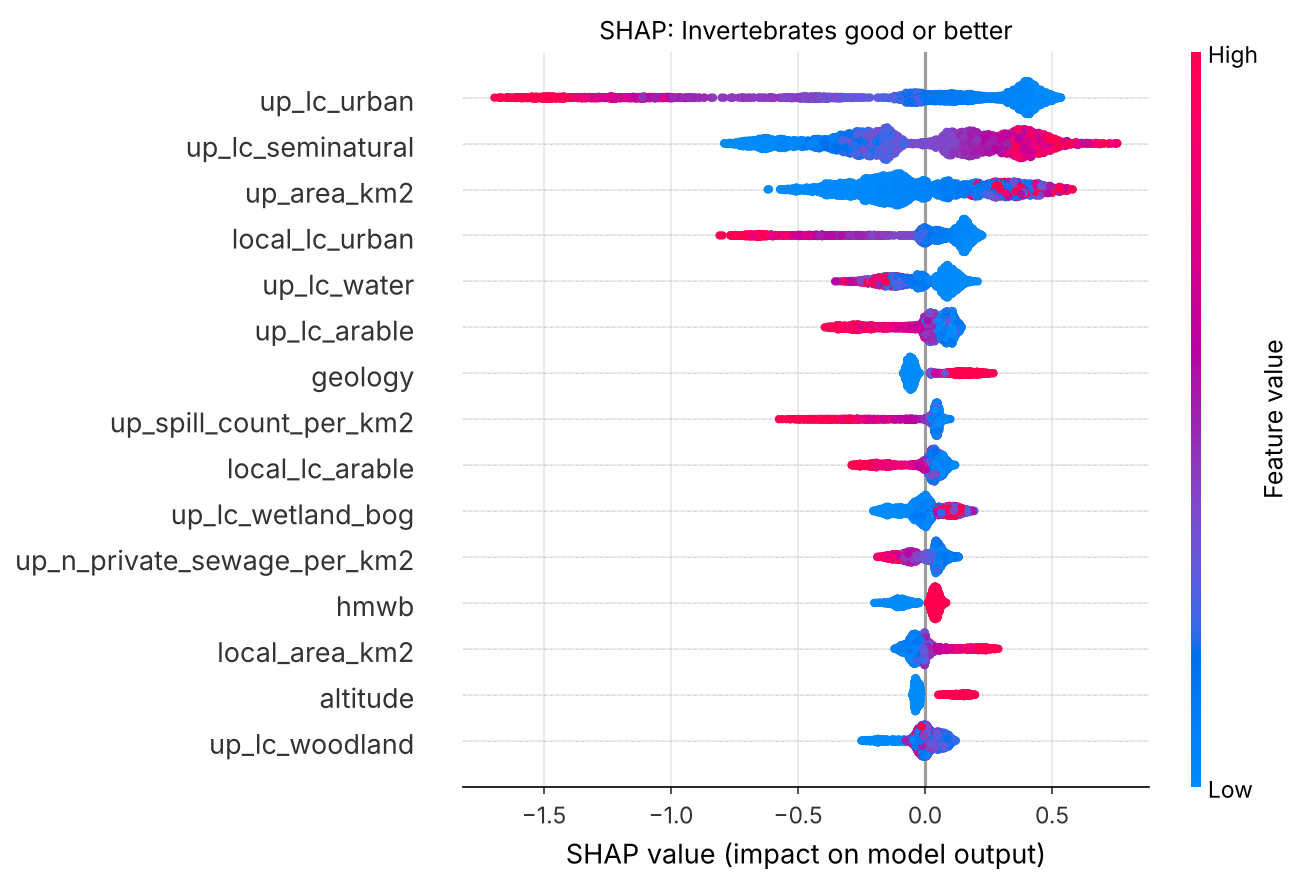

In [5]:
display(Image(FIG / "shap_beeswarm_inv_good.png"))

## Shape of the main effects

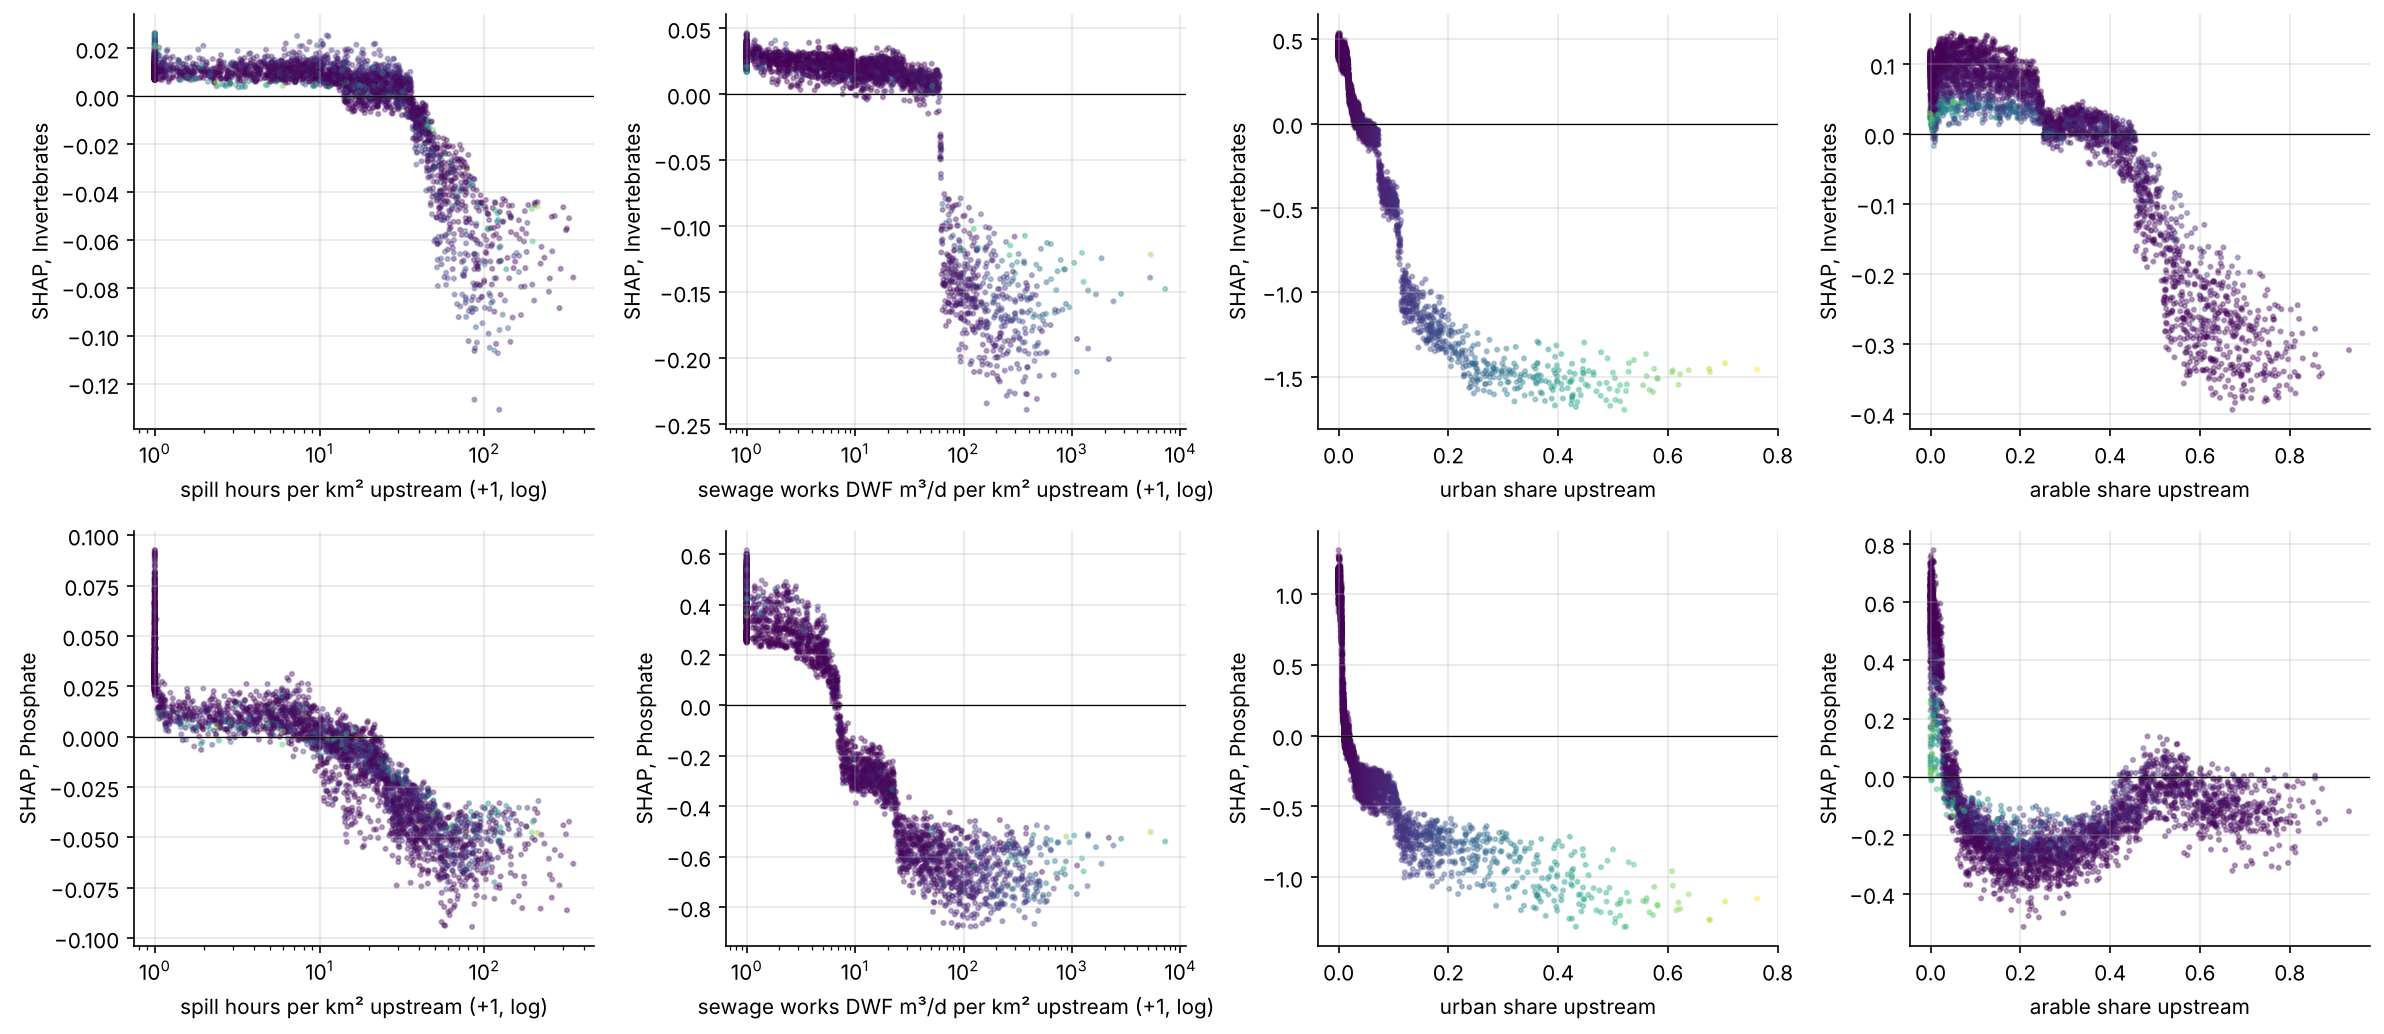

In [6]:
display(Image(FIG / "shap_dependence.png"))

Points are coloured by upstream urban share. The monotone constraints make every curve one-directional;
what the data decides is where each effect bites and how hard.

## Does the model blame the same pressures as the Environment Agency?

For every failing water body the EA records **Reasons for Not Achieving Good** (RNAG): the sector and
activity its staff judged responsible. These were never shown to the model. If the model's SHAP blame for
a pressure group ranks water bodies the way the EA's flags do (AUC > 0.5), the explanation is pointing at
something real.

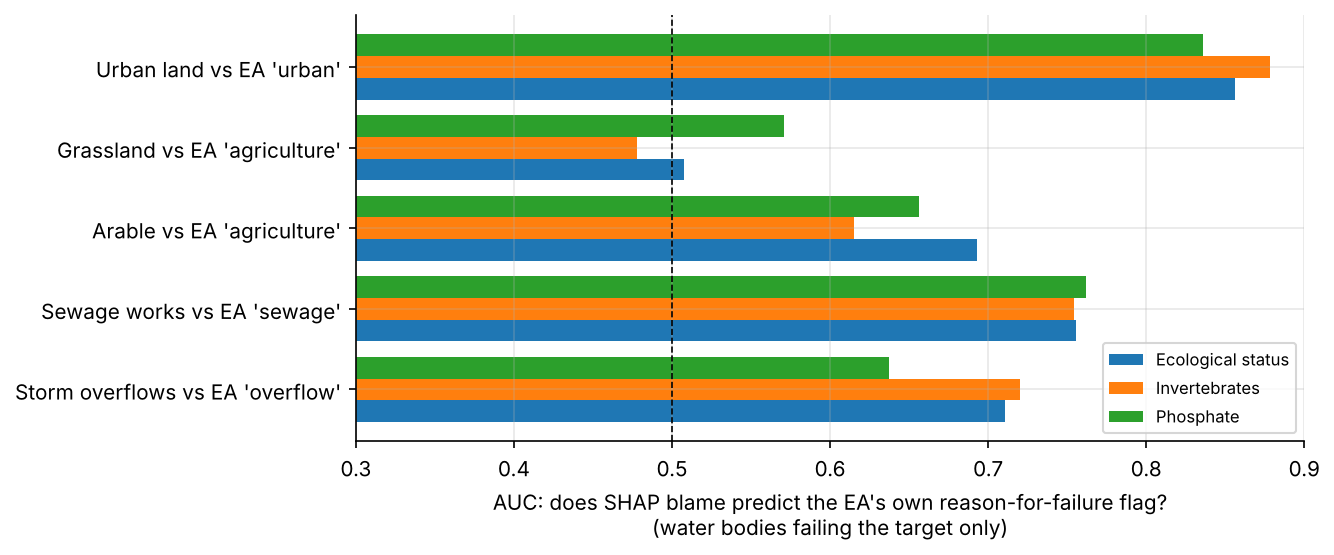

,target,group,rnag_flag,n_failing,flag_rate,auc
0,eco_good,Storm overflows,rnag_overflow,3203,0.153,0.711
1,eco_good,Sewage works,rnag_sewage,3203,0.559,0.756
2,eco_good,Arable,rnag_agriculture,3203,0.705,0.693
3,eco_good,Grassland,rnag_agriculture,3203,0.705,0.507
4,eco_good,Urban land,rnag_urban,3203,0.290,0.856
5,inv_good,Storm overflows,rnag_overflow,864,0.288,0.720
6,inv_good,Sewage works,rnag_sewage,864,0.653,0.754
7,inv_good,Arable,rnag_agriculture,864,0.696,0.615
8,inv_good,Grassland,rnag_agriculture,864,0.696,0.478
9,inv_good,Urban land,rnag_urban,864,0.502,0.878


In [7]:
display(Image(FIG / "rnag_agreement.png"))
pd.read_csv(T / "rnag_agreement.csv").round(3)